<a href="https://colab.research.google.com/github/vk-web06/numerical-method/blob/main/Frozen_meat_quality/notebooks/Frozen_Meat_Packaging_Quality_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Frozen-meat Packaging Quality — Simple Final Notebook


**Goal:** detect five defect classes in pork-rasher packaging images using object detection.

**Classes:** `loose-meat`, `packaging-error`, `twisted-meat`, `unsealed`, `wrinkle`.

**Workflow:** dataset → audit → smoke test → YOLO26n baseline → YOLO26s alternative → validation comparison → simple sensitivity check → final test → predictions → save results.

> Use **T4 GPU** in Google Colab and run the cells from top to bottom.


## 1. Install libraries

In [12]:
!pip install -q -U roboflow ultralytics


## 2. Import libraries and check GPU

In [13]:
import os
import time
import yaml
import random
import shutil
from pathlib import Path
from collections import Counter

import cv2
import torch
import pandas as pd
import matplotlib.pyplot as plt

from roboflow import Roboflow
from ultralytics import YOLO

assert torch.cuda.is_available(), "Aktifkan T4 GPU: Runtime > Change runtime type > T4 GPU"
device = 0

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4
PyTorch: 2.11.0+cu130


## 3. Download dataset from Roboflow

The API key is typed at runtime so it is not stored in the notebook.

In [15]:
from getpass import getpass

ROBOFLOW_API_KEY = getpass("Enter Roboflow API Key : ")

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("hello-2aqe0").project("pork-rasher-error-packaging")
version = project.version(4)
dataset = version.download("yolo26")

dataset_path = Path(dataset.location)
print("Dataset:", dataset_path)


Enter Roboflow API Key : ··········
loading Roboflow workspace...
loading Roboflow project...
Dataset: /content/Pork-Rasher-Error(Packaging)-4


## 4. Read classes and audit the dataset

In [16]:
yaml_path = dataset_path / "data.yaml"

with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)

class_names = data["names"]
if isinstance(class_names, dict):
    class_names = [class_names[i] for i in sorted(class_names)]

print("Classes:", class_names)

rows = []

for split in ["train", "valid", "test"]:
    image_dir = dataset_path / split / "images"
    label_dir = dataset_path / split / "labels"

    images = [p for p in image_dir.glob("*") if p.is_file()]
    labels = list(label_dir.glob("*.txt"))

    counts = Counter()
    empty_labels = 0

    for label_file in labels:
        lines = [line.strip() for line in label_file.read_text().splitlines() if line.strip()]

        if not lines:
            empty_labels += 1
            continue

        for line in lines:
            class_id = int(line.split()[0])
            counts[class_id] += 1

    row = {
        "split": split,
        "images": len(images),
        "labels": len(labels),
        "empty_labels": empty_labels,
    }

    for class_id, class_name in enumerate(class_names):
        row[class_name] = counts[class_id]

    rows.append(row)

audit_df = pd.DataFrame(rows)
display(audit_df)

audit_df.to_csv("/content/dataset_audit.csv", index=False)
print("Total images:", audit_df["images"].sum())


Classes: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']


,split,images,labels,empty_labels,loose-meat,packaging-error,twisted-meat,unsealed,wrinkle
0,train,3349,3349,684,66,1712,72,1055,18
1,valid,120,120,14,3,34,3,81,0
2,test,80,80,12,3,23,4,49,0


Total images: 3549


### Important dataset limitation

The class distribution is very imbalanced. If a class has zero validation/test annotations, its performance cannot be properly evaluated on that split.


## 4.1 Dataset Error Check

This section checks missing labels, missing images, empty labels, invalid YOLO rows, invalid class IDs, and coordinates outside the 0–1 range. Empty labels are recorded for analysis but may be valid no-defect images.


In [17]:
from pathlib import Path
import pandas as pd

errors = []

image_extensions = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

for split in ["train", "valid", "test"]:

    image_dir = Path(dataset_path) / split / "images"
    label_dir = Path(dataset_path) / split / "labels"

    image_files = [
        p for p in image_dir.glob("*")
        if p.suffix.lower() in image_extensions
    ]

    label_files = list(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in image_files}
    label_stems = {p.stem for p in label_files}

    # 1. Image without label file
    for image in image_files:
        if image.stem not in label_stems:
            errors.append({
                "split": split,
                "file": image.name,
                "error_type": "missing_label",
                "detail": "Image does not have a label file"
            })

    # 2. Label without image
    for label in label_files:
        if label.stem not in image_stems:
            errors.append({
                "split": split,
                "file": label.name,
                "error_type": "missing_image",
                "detail": "Label file does not have a matching image"
            })

    # 3. Check contents of each label
    for label in label_files:

        lines = [
            line.strip()
            for line in label.read_text().splitlines()
            if line.strip()
        ]

        # Empty label can be a valid no-defect image,
        # but we still record it for dataset analysis.
        if len(lines) == 0:
            errors.append({
                "split": split,
                "file": label.name,
                "error_type": "empty_label",
                "detail": "No object annotation in this image"
            })
            continue

        for line_number, line in enumerate(lines, start=1):

            values = line.split()

            # YOLO format should contain:
            # class_id x_center y_center width height
            if len(values) != 5:
                errors.append({
                    "split": split,
                    "file": label.name,
                    "error_type": "invalid_format",
                    "detail": f"Line {line_number}: expected 5 values"
                })
                continue

            try:
                class_id = int(values[0])
                x_center, y_center, width, height = map(float, values[1:5])

                # Invalid class ID
                if class_id < 0 or class_id >= len(class_names):
                    errors.append({
                        "split": split,
                        "file": label.name,
                        "error_type": "invalid_class_id",
                        "detail": f"Line {line_number}: class ID {class_id}"
                    })

                # YOLO coordinates should normally be between 0 and 1
                if not all(
                    0 <= value <= 1
                    for value in [x_center, y_center, width, height]
                ):
                    errors.append({
                        "split": split,
                        "file": label.name,
                        "error_type": "invalid_coordinate",
                        "detail": f"Line {line_number}: coordinate outside 0-1"
                    })

            except ValueError:
                errors.append({
                    "split": split,
                    "file": label.name,
                    "error_type": "invalid_value",
                    "detail": f"Line {line_number}: non-numeric value"
                })


# Convert result to DataFrame
dataset_errors_df = pd.DataFrame(errors)

# Save result
error_file = "/content/dataset_errors.csv"
dataset_errors_df.to_csv(error_file, index=False)

print("=== DATASET ERROR CHECK ===")
print("Total recorded issues:", len(dataset_errors_df))

if len(dataset_errors_df) > 0:
    display(dataset_errors_df.head(20))

    print("\nSummary:")
    display(
        dataset_errors_df
        .groupby(["split", "error_type"])
        .size()
        .reset_index(name="count")
    )
else:
    print("No dataset errors found.")

print("\nSaved to:", error_file)

=== DATASET ERROR CHECK ===
Total recorded issues: 710


,split,file,error_type,detail
0,train,frame_with_red_5089_jpg.rf.2fcaf1a26a976c2fb01...,empty_label,No object annotation in this image
1,train,frame_with_red_432_jpg.rf.8be4a0fe2178858a850d...,empty_label,No object annotation in this image
2,train,frame_with_red_4222_jpg.rf.c631a5756d23f459f82...,empty_label,No object annotation in this image
3,train,frame_with_red_2309_jpg.rf.9beda88a84da0295e46...,empty_label,No object annotation in this image
4,train,frame_with_red_6328_jpg.rf.6927c5176eb60c551dc...,empty_label,No object annotation in this image
5,train,frame_with_red_1839_jpg.rf.f3ff3dc6aeb4b5d3074...,empty_label,No object annotation in this image
6,train,frame_with_red_5856_jpg.rf.f63e3a77f6ba2e41eb3...,empty_label,No object annotation in this image
7,train,frame_with_red_9690_jpg.rf.11d5833c2a0bb4cc641...,empty_label,No object annotation in this image
8,train,frame_with_red_1215_jpg.rf.6bdf54c33d8642ce39f...,empty_label,No object annotation in this image
9,train,frame_with_red_37_jpg.rf.5b1caaa1b0b27d2f483b9...,empty_label,No object annotation in this image



Summary:


,split,error_type,count
0,test,empty_label,12
1,train,empty_label,684
2,valid,empty_label,14



Saved to: /content/dataset_errors.csv


## 5. Show sample annotations

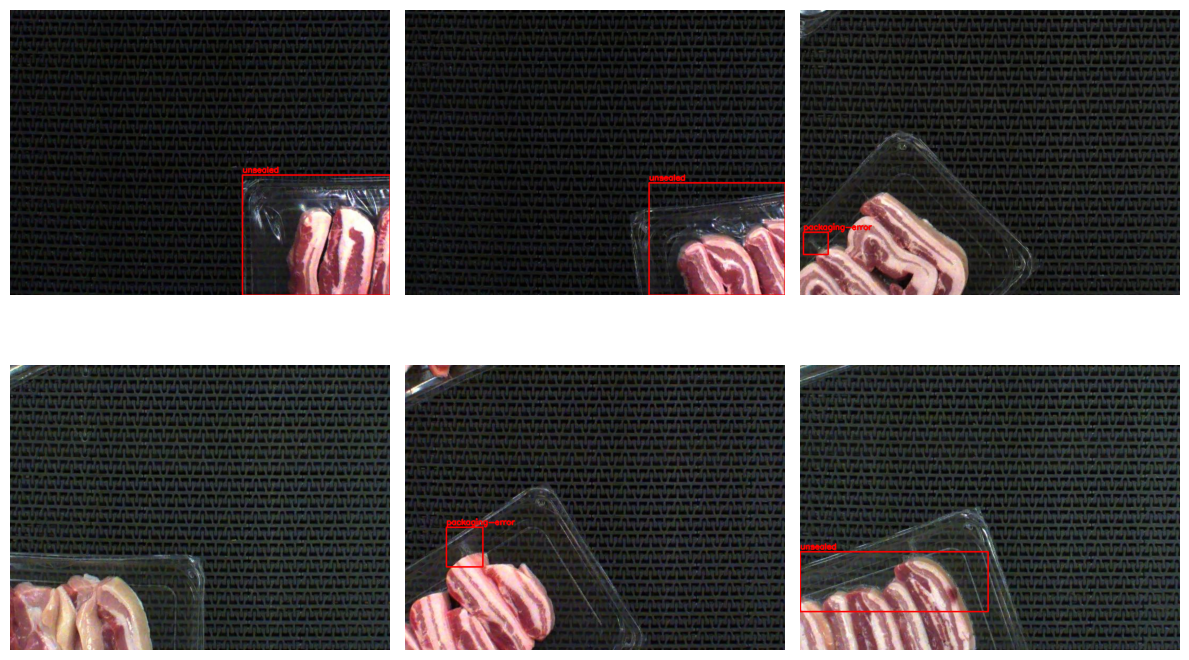

In [ ]:
def draw_labels(image_path, label_path):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            if not line.strip():
                continue

            values = line.split()
            class_id = int(values[0])
            xc, yc, bw, bh = map(float, values[1:5])

            x1 = int((xc - bw / 2) * width)
            y1 = int((yc - bh / 2) * height)
            x2 = int((xc + bw / 2) * width)
            y2 = int((yc + bh / 2) * height)

            cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
            cv2.putText(
                image,
                class_names[class_id],
                (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                2,
            )

    return image


train_images = [p for p in (dataset_path / "train" / "images").glob("*") if p.is_file()]
samples = random.sample(train_images, min(6, len(train_images)))

plt.figure(figsize=(12, 8))

for i, image_path in enumerate(samples):
    label_path = dataset_path / "train" / "labels" / f"{image_path.stem}.txt"

    plt.subplot(2, 3, i + 1)
    plt.imshow(draw_labels(image_path, label_path))
    plt.axis("off")

plt.tight_layout()
plt.show()


## 6. Create clean YOLO YAML

In [ ]:
clean_yaml = "/content/pork_rasher.yaml"

dataset_config = {
    "path": str(dataset_path),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(class_names),
    "names": class_names,
}

with open(clean_yaml, "w") as file:
    yaml.safe_dump(dataset_config, file, sort_keys=False)

print(open(clean_yaml).read())


path: /content/Pork-Rasher-Error(Packaging)-4
train: train/images
val: valid/images
test: test/images
nc: 5
names:
- loose-meat
- packaging-error
- twisted-meat
- unsealed
- wrinkle



# Training

## 7. Smoke test — 1 epoch

This only checks that the training pipeline works. Do not use its metrics as the final project result.


In [ ]:
smoke_model = YOLO("yolo26n.pt")

smoke_model.train(
    data=clean_yaml,
    epochs=1,
    imgsz=640,
    batch=16,
    device=device,
    workers=2,
    seed=42,
    project="/content/frozen_meat_runs",
    name="smoke_test",
    exist_ok=True,
)


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pork_rasher.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_test, nbs=64, nms=None, opset=None, optimize=False, optimiz

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x785eac800410>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

## 8. Baseline model — YOLO26n

Train the smaller model for up to 30 epochs.


In [ ]:
start = time.time()

baseline_model = YOLO("yolo26n.pt")
baseline_model.train(
    data=clean_yaml,
    epochs=30,
    imgsz=640,
    batch=16,
    device=device,
    patience=10,
    workers=2,
    seed=42,
    project="/content/frozen_meat_runs",
    name="baseline_yolo26n",
    exist_ok=True,
    plots=True,
)

baseline_time = (time.time() - start) / 60
print("Training time:", round(baseline_time, 2), "minutes")


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pork_rasher.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolo26n, nbs=64, nms=None, opset=None, optimize=False, 

## 9. Validate baseline model

In [ ]:
baseline_path = "/content/frozen_meat_runs/baseline_yolo26n/weights/best.pt"
baseline = YOLO(baseline_path)

baseline_val = baseline.val(
    data=clean_yaml,
    split="val",
    imgsz=640,
    device=device,
    plots=True,
    project="/content/frozen_meat_runs",
    name="baseline_validation",
    exist_ok=True,
)

baseline_metrics = {
    "model": "YOLO26n",
    "precision": float(baseline_val.box.mp),
    "recall": float(baseline_val.box.mr),
    "mAP50": float(baseline_val.box.map50),
    "mAP50_95": float(baseline_val.box.map),
    "inference_ms": float(baseline_val.speed["inference"]),
    "train_time_min": baseline_time,
}

baseline_metrics


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,811 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1956.3±546.2 MB/s, size: 66.6 KB)
val: Scanning /content/Pork-Rasher-Error(Packaging)-4/valid/labels.cache... 120 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 36.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.3it/s 6.4s
                   all        120        121      0.857      0.468      0.559      0.364
            loose-meat          3          3      0.833      0.333      0.335      0.235
       packaging-error         23         34      0.801      0.294      0.403      0.162
          twisted-meat          3          3      0.881      0.333      0.555      0.411
              unsealed         81         81      0.914      0.913      0.944      0.648
Speed: 6.1ms preprocess

{'model': 'YOLO26n',
 'precision': 0.8572682202006373,
 'recall': 0.4684606302518932,
 'mAP50': 0.5592863752630037,
 'mAP50_95': 0.36384666219217443,
 'inference_ms': 12.472528149999107,
 'train_time_min': 28.500457334518433}

## 10. Alternative model — YOLO26s



The alternative uses the same settings. Only the model size changes from `n` to `s`.


In [ ]:
start = time.time()

alternative_model = YOLO("yolo26s.pt")
alternative_model.train(
    data=clean_yaml,
    epochs=30,
    imgsz=640,
    batch=16,
    device=device,
    patience=10,
    workers=2,
    seed=42,
    project="/content/frozen_meat_runs",
    name="alternative_yolo26s",
    exist_ok=True,
    plots=True,
)

alternative_time = (time.time() - start) / 60
print("Training time:", round(alternative_time, 2), "minutes")


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pork_rasher.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=alternative_yolo26s, nbs=64, nms=None, opset=None, optimize=Fals

## 11. Validate alternative model

In [ ]:
alternative_path = "/content/frozen_meat_runs/alternative_yolo26s/weights/best.pt"
alternative = YOLO(alternative_path)

alternative_val = alternative.val(
    data=clean_yaml,
    split="val",
    imgsz=640,
    device=device,
    plots=True,
    project="/content/frozen_meat_runs",
    name="alternative_validation",
    exist_ok=True,
)

alternative_metrics = {
    "model": "YOLO26s",
    "precision": float(alternative_val.box.mp),
    "recall": float(alternative_val.box.mr),
    "mAP50": float(alternative_val.box.map50),
    "mAP50_95": float(alternative_val.box.map),
    "inference_ms": float(alternative_val.speed["inference"]),
    "train_time_min": alternative_time,
}

alternative_metrics


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,467,115 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1762.1±500.2 MB/s, size: 66.6 KB)
val: Scanning /content/Pork-Rasher-Error(Packaging)-4/valid/labels.cache... 120 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 33.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.5it/s 5.3s
                   all        120        121      0.691      0.697      0.659      0.398
            loose-meat          3          3      0.911      0.667      0.682      0.458
       packaging-error         23         34       0.35      0.529      0.363      0.119
          twisted-meat          3          3       0.77      0.667      0.665      0.367
              unsealed         81         81      0.733      0.926      0.925       0.65
Speed: 7.2ms preproces

{'model': 'YOLO26s',
 'precision': 0.6911933626478585,
 'recall': 0.6971677559912854,
 'mAP50': 0.6587435557081294,
 'mAP50_95': 0.39832025034667995,
 'inference_ms': 11.200133533323726,
 'train_time_min': 31.553083662192027}

## 12. Compare models and select the best one

The final model is selected using **validation mAP@50-95**. The test set is still untouched.


In [ ]:
comparison_df = pd.DataFrame([baseline_metrics, alternative_metrics])
display(comparison_df.round(4))

comparison_df.to_csv("/content/model_comparison.csv", index=False)

best_row = comparison_df.loc[comparison_df["mAP50_95"].idxmax()]
final_model_name = best_row["model"]

if final_model_name == "YOLO26s":
    final_model_path = alternative_path
else:
    final_model_path = baseline_path

print("Selected model:", final_model_name)

final_model = YOLO(final_model_path)


,model,precision,recall,mAP50,mAP50_95,inference_ms,train_time_min
0,YOLO26n,0.8573,0.4685,0.5593,0.3638,12.4725,28.5005
1,YOLO26s,0.6912,0.6972,0.6587,0.3983,11.2001,31.5531


Selected model: YOLO26s


## 13. Simple sensitivity check

Evaluate the selected model at two input sizes. This gives a simple accuracy/speed sensitivity comparison.


In [ ]:
sensitivity_rows = []

for image_size in [512, 640]:
    result = final_model.val(
        data=clean_yaml,
        split="val",
        imgsz=image_size,
        device=device,
        plots=False,
        project="/content/frozen_meat_runs",
        name=f"sensitivity_{image_size}",
        exist_ok=True,
    )

    sensitivity_rows.append({
        "image_size": image_size,
        "mAP50_95": float(result.box.map),
        "inference_ms": float(result.speed["inference"]),
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df.round(4))
sensitivity_df.to_csv("/content/sensitivity.csv", index=False)


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,467,115 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2373.6±875.3 MB/s, size: 64.6 KB)
val: Scanning /content/Pork-Rasher-Error(Packaging)-4/valid/labels.cache... 120 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 38.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 5.5it/s 1.5s
                   all        120        121      0.785       0.66      0.671      0.385
            loose-meat          3          3          1      0.561      0.702      0.411
       packaging-error         23         34      0.438        0.5      0.384      0.113
          twisted-meat          3          3      0.912      0.667      0.665      0.366
              unsealed         81         81      0.789      0.914      0.935      0.652
Speed: 0.5ms preproces

,image_size,mAP50_95,inference_ms
0,512,0.3855,6.9807
1,640,0.3983,8.7405


## 14. Final test

The test set is used only after the model has been selected.


In [ ]:
final_test = final_model.val(
    data=clean_yaml,
    split="test",
    imgsz=640,
    device=device,
    plots=True,
    project="/content/frozen_meat_runs",
    name="final_test",
    exist_ok=True,
)

final_metrics = {
    "precision": float(final_test.box.mp),
    "recall": float(final_test.box.mr),
    "mAP50": float(final_test.box.map50),
    "mAP50_95": float(final_test.box.map),
}

print(final_metrics)


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,467,115 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 21.3±13.2 MB/s, size: 65.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/Pork-Rasher-Error(Packaging)-4/test/labels... 80 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 409.6it/s 0.2s
val: New cache created: /content/Pork-Rasher-Error(Packaging)-4/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.7it/s 2.9s
                   all         80         79      0.439      0.651       0.59      0.278
            loose-meat          2          3      0.729      0.917      0.913      0.312
       packaging-error         16         23      0.283      0.60

## 15. Show example predictions


0: 480x640 1 unsealed, 11.3ms
1: 480x640 2 unsealeds, 11.3ms
2: 480x640 1 unsealed, 11.3ms
3: 480x640 1 packaging-error, 11.3ms
4: 480x640 (no detections), 11.3ms
5: 480x640 1 unsealed, 11.3ms
Speed: 1.4ms preprocess, 11.3ms inference, 0.9ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/frozen_meat_runs/final_predictions


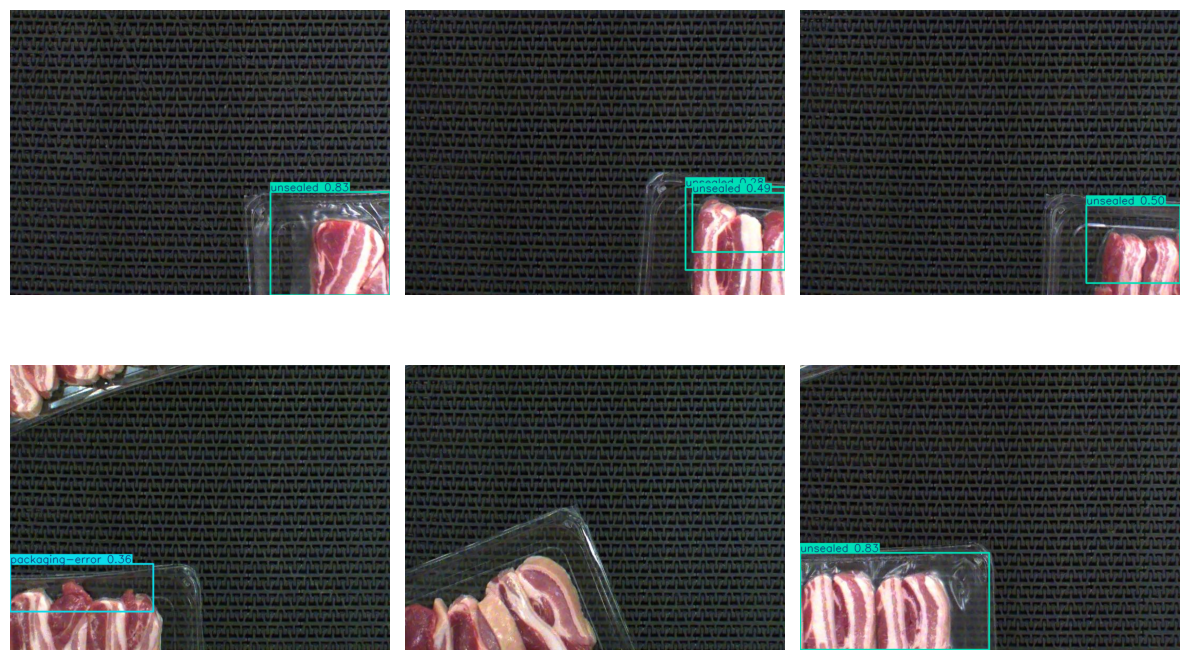

In [ ]:
test_images = [p for p in (dataset_path / "test" / "images").glob("*") if p.is_file()]
sample_test = random.sample(test_images, min(6, len(test_images)))

prediction_results = final_model.predict(
    source=[str(p) for p in sample_test],
    conf=0.25,
    imgsz=640,
    device=device,
    save=True,
    project="/content/frozen_meat_runs",
    name="final_predictions",
    exist_ok=True,
)

plt.figure(figsize=(12, 8))

for i, result in enumerate(prediction_results[:6]):
    image = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()


## 16. Save final model and result summary

In [ ]:
final_export_path = "/content/best_frozen_meat.pt"
shutil.copy(final_model_path, final_export_path)

summary_text = f"""
FROZEN-MEAT PACKAGING QUALITY

Selected model: {final_model_name}

BASELINE VALIDATION
Precision: {baseline_metrics['precision']:.4f}
Recall: {baseline_metrics['recall']:.4f}
mAP@50: {baseline_metrics['mAP50']:.4f}
mAP@50-95: {baseline_metrics['mAP50_95']:.4f}

ALTERNATIVE VALIDATION
Precision: {alternative_metrics['precision']:.4f}
Recall: {alternative_metrics['recall']:.4f}
mAP@50: {alternative_metrics['mAP50']:.4f}
mAP@50-95: {alternative_metrics['mAP50_95']:.4f}

FINAL TEST
Precision: {final_metrics['precision']:.4f}
Recall: {final_metrics['recall']:.4f}
mAP@50: {final_metrics['mAP50']:.4f}
mAP@50-95: {final_metrics['mAP50_95']:.4f}

LIMITATIONS
- The dataset is strongly imbalanced.
- Some classes have very few validation/test examples.
- The wrinkle class may not have validation/test examples.
- Each model is trained once with seed 42.
"""

Path("/content/result_summary.txt").write_text(summary_text)
print(summary_text)

print("Final model:", final_export_path)
print("Comparison:", "/content/model_comparison.csv")
print("Summary:", "/content/result_summary.txt")



FROZEN-MEAT PACKAGING QUALITY

Selected model: YOLO26s

BASELINE VALIDATION
Precision: 0.8573
Recall: 0.4685
mAP@50: 0.5593
mAP@50-95: 0.3638

ALTERNATIVE VALIDATION
Precision: 0.6912
Recall: 0.6972
mAP@50: 0.6587
mAP@50-95: 0.3983

FINAL TEST
Precision: 0.4394
Recall: 0.6513
mAP@50: 0.5902
mAP@50-95: 0.2776

LIMITATIONS
- The dataset is strongly imbalanced.
- Some classes have very few validation/test examples.
- The wrinkle class may not have validation/test examples.
- Each model is trained once with seed 42.

Final model: /content/best_frozen_meat.pt
Comparison: /content/model_comparison.csv
Summary: /content/result_summary.txt


# Files to keep after training

Save these files for the GitHub repository, report, and presentation:

- `best_frozen_meat.pt`
- `model_comparison.csv`
- `sensitivity.csv`
- `dataset_audit.csv`
- `dataset_errors.csv`
- `result_summary.txt`
- `results.png` and confusion matrix from the important runs
- several images from `final_predictions`


Do not invent metrics. Use only the values generated by the notebook.


## 17. Create one ZIP with the main outputs

This optional cell packages the final model, CSV/TXT results, and Ultralytics run folders for backup.


In [ ]:
export_dir = Path('/content/frozen_meat_export')
if export_dir.exists():
    shutil.rmtree(export_dir)
export_dir.mkdir()

for file_path in [
    '/content/best_frozen_meat.pt',
    '/content/dataset_audit.csv',
    '/content/dataset_errors.csv',
    '/content/model_comparison.csv',
    '/content/sensitivity.csv',
    '/content/result_summary.txt',
]:
    path = Path(file_path)
    if path.exists():
        shutil.copy(path, export_dir / path.name)

runs_dir = Path('/content/frozen_meat_runs')
if runs_dir.exists():
    shutil.copytree(runs_dir, export_dir / 'frozen_meat_runs')

zip_path = shutil.make_archive('/content/frozen_meat_results', 'zip', export_dir)
print('Output ZIP:', zip_path)
